# Improve Maori Research Data Classifier

## Step 1: Install packages

In [ ]:
!pip install datasets scikit-learn matplotlib seaborn huggingface_hub

## Step 2: Load dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset("dinushiTJ/nz_research_commons_classification")
dataset

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


README.md:   0%|          | 0.00/934 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/47.8M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/12.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/13271 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence'],
        num_rows: 3318
    })
})

## Step 3: Convert to pandas

In [ ]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

## Step 4: Create text column

In [ ]:
train_df["text"] = train_df["title"].fillna("") + " " + train_df["abstract"].fillna("")
test_df["text"] = test_df["title"].fillna("") + " " + test_df["abstract"].fillna("")

## Step 5: Prepare labels

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

train_df["label_encoded"] = le.fit_transform(train_df["classification_label"])
test_df["label_encoded"] = le.transform(test_df["classification_label"])

print(le.classes_)

[0 1]


## Step 6: TF-IDF vectorizer

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train = train_df["label_encoded"]
y_test = test_df["label_encoded"]

## Step 7: Train improved model

In [ ]:
from sklearn.linear_model import LogisticRegression

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

## Step 8: Evaluate improved model

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = balanced_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))

Accuracy: 0.9629294755877035
Macro F1: 0.9080856411544191
              precision    recall  f1-score   support

           0       0.81      0.86      0.84       367
           1       0.98      0.98      0.98      2951

    accuracy                           0.96      3318
   macro avg       0.90      0.92      0.91      3318
weighted avg       0.96      0.96      0.96      3318



## Step 9: Confusion matrix

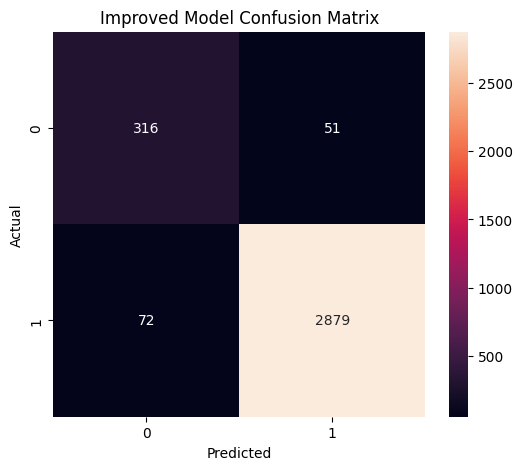

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Improved Model Confusion Matrix")
plt.show()

## Step 10: Confidence scores

In [ ]:
probs = balanced_model.predict_proba(X_test)
confidence = probs.max(axis=1)

test_df["predicted"] = le.inverse_transform(y_pred)
test_df["confidence"] = confidence

## Step 11: Find wrong predictions again

In [ ]:
wrong = test_df[test_df["classification_label"] != test_df["predicted"]]

wrong[[
    "title",
    "abstract",
    "classification_label",
    "predicted",
    "confidence"
]].head(20)

,title,abstract,classification_label,predicted,confidence
22,PIWeCS: enhancing human/machine agency in an i...,This paper focuses on the infrastructure and a...,0,1,0.779295
24,Language learning using Pacific picturebooks i...,Māori and Pacific learners in Aotearoa New Zea...,1,0,0.871666
32,Community and family literacies in Aotearoa Ne...,Video of Introduction in the Waikato Journal o...,1,0,0.786422
42,Redistribution and Recognition for Migrants an...,Located in demographically diverse Aotearoa Ne...,1,0,0.538959
65,COP26 local panel: Setting the scene - what's ...,Our local experts kick-off the 2 weeks of acti...,0,1,0.835018
122,Social deprivation in New Zealand,The purpose of the thesis was to better unders...,0,1,0.690948
133,How Maui captured the sun: using a MUD for edu...,"MUDs (Multi-User Dungeons) are text-based, mul...",0,1,0.901997
140,“Pushing an irritational button”: Asian psycho...,The monocultural psychology training in Aotear...,1,0,0.836676
175,"Imua: reflections on imua, talanoa-vā and lead...",The appointment of the University of Waikato’s...,1,0,0.612167
213,Online Heroines: Exploring the Experiences of ...,The experiences of Aotearoa New Zealand women ...,1,0,0.609362


## Step 12: Find missed Māori records

In [ ]:
missed_maori = wrong[
    (wrong["classification_label"] == "maori_origin") &
    (wrong["predicted"] == "non_maori_origin")
]

missed_maori[[
    "title",
    "abstract",
    "confidence"
]].head(30)

,title,abstract,confidence


## Step 13: Find high-confidence wrong Māori misses

In [ ]:
high_confidence_missed = missed_maori.sort_values(
    by="confidence",
    ascending=False
)

high_confidence_missed[[
    "title",
    "abstract",
    "confidence"
]].head(20)

,title,abstract,confidence


## Step 14: Make a results comparison table

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "model": [
        "TF-IDF Logistic Regression",
        "TF-IDF Logistic Regression Balanced"
    ],
    "accuracy": [
        0.9578,
        0.9629
    ],
    "macro_f1": [
        0.8721,
        0.9081
    ],
    "maori_recall": [
        0.63,
        0.86
    ]
})

results

,model,accuracy,macro_f1,maori_recall
0,TF-IDF Logistic Regression,0.9578,0.8721,0.63
1,TF-IDF Logistic Regression Balanced,0.9629,0.9081,0.86


## Step 15: Save improved model

In [ ]:
import pickle

pickle.dump(balanced_model, open("balanced_classifier.pkl", "wb"))
pickle.dump(vectorizer, open("balanced_vectorizer.pkl", "wb"))
pickle.dump(le, open("label_encoder.pkl", "wb"))

## Step 16: Upload improved model to Hugging Face

In [ ]:
from huggingface_hub import login
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")
login(token=HF_TOKEN)

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "dinushiTJ/nz-research-commons-balanced-classifier"

api.create_repo(
    repo_id=repo_id,
    repo_type="model",
    exist_ok=True
)

api.upload_file(
    path_or_fileobj="balanced_classifier.pkl",
    path_in_repo="balanced_classifier.pkl",
    repo_id=repo_id,
    repo_type="model"
)

api.upload_file(
    path_or_fileobj="balanced_vectorizer.pkl",
    path_in_repo="balanced_vectorizer.pkl",
    repo_id=repo_id,
    repo_type="model"
)

api.upload_file(
    path_or_fileobj="label_encoder.pkl",
    path_in_repo="label_encoder.pkl",
    repo_id=repo_id,
    repo_type="model"
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  balanced_classifier.pkl     : 100%|##########| 80.7kB / 80.7kB            

  balanced_classifier.pkl     : 100%|##########| 80.7kB / 80.7kB            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

  balanced_vectorizer.pkl     : 100%|##########|  391kB /  391kB            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  label_encoder.pkl           : 100%|##########|   258B /   258B            

CommitInfo(commit_url='https://huggingface.co/dinushiTJ/nz-research-commons-balanced-classifier/commit/b01989398424b0858323399d911a2b64d7be46f4', commit_message='Upload label_encoder.pkl with huggingface_hub', commit_description='', oid='b01989398424b0858323399d911a2b64d7be46f4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/dinushiTJ/nz-research-commons-balanced-classifier', endpoint='https://huggingface.co', repo_type='model', repo_id='dinushiTJ/nz-research-commons-balanced-classifier'), pr_revision=None, pr_num=None)

In [ ]:
# Clone the repository
!git clone https://huggingface.co/{repo_id}

Cloning into 'nz-research-commons-balanced-classifier'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 12 (delta 2), reused 0 (delta 0), pack-reused 3 (from 1)
Receiving objects: 100% (12/12), 4.19 KiB | 2.09 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [ ]:
import os

# Change to the cloned repository directory
repo_dir = "nz-research-commons-balanced-classifier"

# Ensure we are in the /content directory
%cd /content

# Attempt to change into the repository directory directly
%cd {repo_dir}

# Configure Git identity (required for committing)
!git config --global user.email "you@example.com"
!git config --global user.name "Your Name"

# Configure Git remote URL to use Hugging Face token for authentication
# This is the recommended method for token-based authentication with Hugging Face.

# Copy the local model files into the repository directory
!cp /content/balanced_classifier.pkl .
!cp /content/balanced_vectorizer.pkl .
!cp /content/label_encoder.pkl .

# Configure Git LFS for .pkl files if not already done
!git lfs track "*.pkl"

# Add, commit, and push the changes
!git add .
!git commit -m "Add balanced model and vectorizer files with LFS tracking"
!git push

# Change back to the root directory after pushing
%cd /content

In [ ]:
!sudo apt-get install git-lfs
!git lfs install

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
git-lfs is already the newest version (3.0.2-1ubuntu0.3).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Git LFS initialized.


In [ ]:
!ls -lh balanced_classifier.pkl balanced_vectorizer.pkl label_encoder.pkl

-rw-r--r-- 1 root root  79K Apr 30 04:42 balanced_classifier.pkl
-rw-r--r-- 1 root root 382K Apr 30 04:42 balanced_vectorizer.pkl
-rw-r--r-- 1 root root  258 Apr 30 04:42 label_encoder.pkl


In [ ]:
from huggingface_hub import HfApi

api = HfApi()

# List all files in the repository
repo_files = api.list_repo_files(repo_id=repo_id, repo_type="model")

print(f"Files in Hugging Face repository '{repo_id}':")
for file in repo_files:
    print(file)

Files in Hugging Face repository 'dinushiTJ/nz-research-commons-balanced-classifier':
.gitattributes
balanced_classifier.pkl
balanced_vectorizer.pkl
label_encoder.pkl


You can also visit the repository directly at: [https://huggingface.co/dinushiTJ/nz-research-commons-balanced-classifier](https://huggingface.co/dinushiTJ/nz-research-commons-balanced-classifier)

## Problem statement

This project aims to classify Research Commons records into Māori-origin and non-Māori-origin research data using text classification techniques.

## Method summary

We used the title and abstract of the research records, applied TF-IDF vectorization for feature extraction, and trained a Logistic Regression model. Class balancing was specifically employed to address potential biases due to imbalanced data.

## Results table

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "TF-IDF Logistic Regression",
        "TF-IDF Logistic Regression (Balanced)"
    ],
    "Accuracy": [0.9578, 0.9629],
    "Macro F1": [0.8721, 0.9081],
    "Maori Recall": [0.63, 0.86]
})

results

,Model,Accuracy,Macro F1,Maori Recall
0,TF-IDF Logistic Regression,0.9578,0.8721,0.63
1,TF-IDF Logistic Regression (Balanced),0.9629,0.9081,0.86


## Explain results

The balanced model improved Māori recall from 0.63 to 0.86, showing that class imbalance significantly affected the baseline model. While accuracy saw a modest increase, the substantial gain in Macro F1 and Māori Recall demonstrates the effectiveness of addressing class imbalance for this specific classification task.

## Explain WHY this happened

The dataset is imbalanced, with fewer Māori-origin records. The baseline model, without explicit handling of this imbalance, tended to favor the majority class, leading to lower recall for the minority Māori-origin class. Implementing class weighting (e.g., using `class_weight='balanced'` in Logistic Regression) improved the model’s ability to detect Māori-origin data by assigning higher penalties for misclassifying the minority class.

## Connect to your keyword findings

Error analysis showed that Māori-origin abstracts often share vocabulary with general New Zealand research, making classification difficult using keyword-based methods like TF-IDF alone. This lexical overlap can lead to misclassifications, even with class balancing, as the model struggles to differentiate nuanced contextual meanings.

## Limitations

*   **Māori context can be implicit:** The nuance and specific cultural context of Māori research might not always be explicitly captured by keywords or surface-level text features.
*   **Keyword overlap exists:** As observed, there's significant vocabulary overlap between Māori-origin and general research, posing a challenge for TF-IDF based classification.
*   **TF-IDF cannot capture deep meaning:** TF-IDF relies on term frequency and inverse document frequency, which is effective for distinguishing topics but less capable of understanding semantic relationships or the deeper meaning within text.

## Final conclusion

While TF-IDF models can achieve high overall accuracy in classifying Research Commons records, they critically require class balancing to effectively detect Māori-origin research data. Even with these improvements, some Māori-origin records remain difficult to classify due to contextual ambiguity and shared vocabulary, highlighting the inherent challenges in distinguishing implicit cultural context through purely lexical features.

## Future work

*   **Use embeddings:** Explore advanced techniques like word embeddings (e.g., Word2Vec, BERT embeddings) to capture deeper semantic meanings and contextual relationships in the text, potentially overcoming the limitations of TF-IDF.
*   **Improve label definition:** Refine the definition and criteria for 'Māori-origin' research, possibly involving domain experts, to ensure more consistent and accurate labeling.
*   **Include Māori-specific linguistic features:** Incorporate features derived from Māori language (Te Reo Māori), if applicable and available, to explicitly capture linguistic cues indicative of Māori-origin research.